In [1]:
import os

In [2]:
os.listdir()

['.ipynb_checkpoints',
 'portfolio.json',
 'profile.json',
 'starbucks_customer_segmentation.ipynb',
 'transcript.json']

In [3]:
import os

In [4]:
os.listdir()

['.ipynb_checkpoints',
 'portfolio.json',
 'profile.json',
 'starbucks_customer_segmentation.ipynb',
 'transcript.json']

In [5]:
import pandas as pd

In [6]:
import numpy as np

In [7]:
import matplotlib.pyplot as plt

In [8]:
import seaborn as sns

In [9]:
portfolio = pd.read_json('portfolio.json', orient='records', lines=True)

In [10]:
profile = pd.read_json('profile.json', orient='records', lines=True)

In [11]:
transcript = pd.read_json('transcript.json', orient='records', lines=True)

In [12]:
print(portfolio.shape, profile.shape, transcript.shape)

(10, 6) (17000, 5) (306534, 4)


In [13]:
portfolio.head()

,reward,channels,difficulty,duration,offer_type,id
0,10,"[email, mobile, social]",10,7,bogo,ae264e3637204a6fb9bb56bc8210ddfd
1,10,"[web, email, mobile, social]",10,5,bogo,4d5c57ea9a6940dd891ad53e9dbe8da0
2,0,"[web, email, mobile]",0,4,informational,3f207df678b143eea3cee63160fa8bed
3,5,"[web, email, mobile]",5,7,bogo,9b98b8c7a33c4b65b9aebfe6a799e6d9
4,5,"[web, email]",20,10,discount,0b1e1539f2cc45b7b9fa7c272da2e1d7


In [14]:
profile.head()

,gender,age,id,became_member_on,income
0,None,118,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN
1,F,55,0610b486422d4921ae7d2bf64640c50b,20170715,112000.0
2,None,118,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN
3,F,75,78afa995795e4d85b5d9ceeca43f5fef,20170509,100000.0
4,None,118,a03223e636434f42ac4c3df47e8bac43,20170804,NaN


In [15]:
profile.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            14825 non-null  object 
 1   age               17000 non-null  int64  
 2   id                17000 non-null  object 
 3   became_member_on  17000 non-null  int64  
 4   income            14825 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 664.2+ KB


In [16]:
profile.describe()

,age,became_member_on,income
count,17000.000000,1.700000e+04,14825.000000
mean,62.531412,2.016703e+07,65404.991568
std,26.738580,1.167750e+04,21598.299410
min,18.000000,2.013073e+07,30000.000000
25%,45.000000,2.016053e+07,49000.000000
50%,58.000000,2.017080e+07,64000.000000
75%,73.000000,2.017123e+07,80000.000000
max,118.000000,2.018073e+07,120000.000000


In [17]:
transcript.head()

,person,event,value,time
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0


In [18]:
transcript.event.value_counts()

event
transaction        138953
offer received      76277
offer viewed        57725
offer completed     33579
Name: count, dtype: int64

In [19]:
profile[profile.age == 118].shape

(2175, 5)

In [20]:
profile[profile.age == 118].head()

,gender,age,id,became_member_on,income
0,None,118,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN
2,None,118,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN
4,None,118,a03223e636434f42ac4c3df47e8bac43,20170804,NaN
6,None,118,8ec6ce2a7e7949b1bf142def7d0e0586,20170925,NaN
7,None,118,68617ca6246f4fbc85e91a2a49552598,20171002,NaN


In [21]:
profile = profile.rename(columns={'id': 'person'})

In [22]:
portfolio = portfolio.rename(columns={'id': 'offer_id'})

In [23]:
profile_clean = profile[profile.age != 118].copy()

In [24]:
profile_clean.shape

(14825, 5)

In [25]:
profile_clean['became_member_on'] = pd.to_datetime(profile_clean['became_member_on'], format='%Y%m%d')
ref_date = profile_clean['became_member_on'].max()
profile_clean['tenure_days'] = (ref_date - profile_clean['became_member_on']).dt.days

In [26]:
transcript['offer_id'] = transcript['value'].apply(lambda x: x.get('offer id', x.get('offer_id')))
transcript['amount'] = transcript['value'].apply(lambda x: x.get('amount'))
transcript['reward'] = transcript['value'].apply(lambda x: x.get('reward'))
transcript = transcript.drop(columns='value')

In [27]:
transcript = transcript[transcript.person.isin(profile_clean.person)]

In [28]:
for ch in ['web', 'email', 'mobile', 'social']:
    portfolio[ch] = portfolio['channels'].apply(lambda x: int(ch in x))
portfolio = portfolio.drop(columns='channels')

In [29]:
profile_clean.info()
transcript.head()
portfolio

<class 'pandas.core.frame.DataFrame'>
Index: 14825 entries, 1 to 16999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   gender            14825 non-null  object        
 1   age               14825 non-null  int64         
 2   person            14825 non-null  object        
 3   became_member_on  14825 non-null  datetime64[ns]
 4   income            14825 non-null  float64       
 5   tenure_days       14825 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2), object(2)
memory usage: 810.7+ KB


,reward,difficulty,duration,offer_type,offer_id,web,email,mobile,social
0,10,10,7,bogo,ae264e3637204a6fb9bb56bc8210ddfd,0,1,1,1
1,10,10,5,bogo,4d5c57ea9a6940dd891ad53e9dbe8da0,1,1,1,1
2,0,0,4,informational,3f207df678b143eea3cee63160fa8bed,1,1,1,0
3,5,5,7,bogo,9b98b8c7a33c4b65b9aebfe6a799e6d9,1,1,1,0
4,5,20,10,discount,0b1e1539f2cc45b7b9fa7c272da2e1d7,1,1,0,0
5,3,7,7,discount,2298d6c36e964ae4a3e7e9706d1fb8c2,1,1,1,1
6,2,10,10,discount,fafdcd668e3743c1bb461111dcafc2a4,1,1,1,1
7,0,0,3,informational,5a8bc65990b245e5a138643cd4eb9837,0,1,1,1
8,5,5,5,bogo,f19421c1d4aa40978ebb69ca19b0e20d,1,1,1,1
9,2,10,7,discount,2906b810c7d4411798c6938adc9daaa5,1,1,1,0


In [30]:
offers = transcript[transcript.event != 'transaction'].copy()
trans = transcript[transcript.event == 'transaction'].copy()
offers.shape, trans.shape

((148805, 6), (123957, 6))

In [31]:
offer_counts = offers.pivot_table(index='person', columns='event',
                                  values='time', aggfunc='count', fill_value=0)
offer_counts.columns = [c.replace('offer ', '') for c in offer_counts.columns]
offer_counts = offer_counts.reset_index()
offer_counts.head()

,person,completed,received,viewed
0,0009655768c64bdeb2e877511632db8f,3,5,4
1,0011e0d4e6b944f998e987f904e8c1e5,3,5,5
2,0020c2b971eb4e9188eac86d93036a77,3,5,3
3,0020ccbbb6d84e358d3414a3ff76cffd,3,4,4
4,003d66b6608740288d6cc97a6903f4f0,3,5,4


In [32]:
offer_counts['view_rate'] = offer_counts['viewed'] / offer_counts['received']
offer_counts['completion_rate'] = offer_counts['completed'] / offer_counts['received']
offer_counts = offer_counts.replace([np.inf, -np.inf], np.nan).fillna(0)

In [33]:
spend = trans.groupby('person')['amount'].agg(
    total_spend='sum',
    n_transactions='count',
    avg_transaction='mean'
).reset_index()
spend.head()

,person,total_spend,n_transactions,avg_transaction
0,0009655768c64bdeb2e877511632db8f,127.60,8,15.950000
1,0011e0d4e6b944f998e987f904e8c1e5,79.46,5,15.892000
2,0020c2b971eb4e9188eac86d93036a77,196.86,8,24.607500
3,0020ccbbb6d84e358d3414a3ff76cffd,154.05,12,12.837500
4,003d66b6608740288d6cc97a6903f4f0,48.34,18,2.685556


In [34]:
customers = (profile_clean
             .merge(offer_counts, on='person', how='left')
             .merge(spend, on='person', how='left'))
customers = customers.fillna(0)
customers.shape

(14825, 14)

In [35]:
offers_full = (offers
               .merge(portfolio, on='offer_id', how='left')
               .merge(profile_clean, on='person', how='left'))
offers_full.head()

,person,event,time,offer_id,amount,reward_x,reward_y,difficulty,duration,offer_type,web,email,mobile,social,gender,age,became_member_on,income,tenure_days
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,0,9b98b8c7a33c4b65b9aebfe6a799e6d9,NaN,NaN,5,5,7,bogo,1,1,1,0,F,75,2017-05-09,100000.0,443
1,e2127556f4f64592b11af22de27a7932,offer received,0,2906b810c7d4411798c6938adc9daaa5,NaN,NaN,2,10,7,discount,1,1,1,0,M,68,2018-04-26,70000.0,91
2,389bc3fa690240e798340f5a15918d5c,offer received,0,f19421c1d4aa40978ebb69ca19b0e20d,NaN,NaN,5,5,5,bogo,1,1,1,1,M,65,2018-02-09,53000.0,167
3,2eeac8d8feae4a8cad5a6af0499a211d,offer received,0,3f207df678b143eea3cee63160fa8bed,NaN,NaN,0,0,4,informational,1,1,1,0,M,58,2017-11-11,51000.0,257
4,aa4862eba776480b8bb9c68455b8c2e1,offer received,0,0b1e1539f2cc45b7b9fa7c272da2e1d7,NaN,NaN,5,20,10,discount,1,1,0,0,F,61,2017-09-11,57000.0,318


In [36]:
customers.info()
customers.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14825 entries, 0 to 14824
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   gender            14825 non-null  object        
 1   age               14825 non-null  int64         
 2   person            14825 non-null  object        
 3   became_member_on  14825 non-null  datetime64[ns]
 4   income            14825 non-null  float64       
 5   tenure_days       14825 non-null  int64         
 6   completed         14825 non-null  float64       
 7   received          14825 non-null  float64       
 8   viewed            14825 non-null  float64       
 9   view_rate         14825 non-null  float64       
 10  completion_rate   14825 non-null  float64       
 11  total_spend       14825 non-null  float64       
 12  n_transactions    14825 non-null  float64       
 13  avg_transaction   14825 non-null  float64       
dtypes: datetime64[ns](1), 

,age,became_member_on,income,tenure_days,completed,received,viewed,view_rate,completion_rate,total_spend,n_transactions,avg_transaction
count,14825.000000,14825,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000,14825.000000
mean,54.393524,2017-02-18 12:30:15.419898880,65404.991568,522.478988,2.188465,4.485734,3.363238,0.753270,0.487377,117.028155,8.361349,14.909689
min,18.000000,2013-07-29 00:00:00,30000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42.000000,2016-05-20 00:00:00,49000.000000,208.000000,1.000000,4.000000,2.000000,0.600000,0.200000,31.450000,4.000000,3.701429
50%,55.000000,2017-08-02 00:00:00,64000.000000,358.000000,2.000000,5.000000,3.000000,0.800000,0.500000,87.040000,7.000000,13.988333
75%,66.000000,2017-12-30 00:00:00,80000.000000,797.000000,3.000000,5.000000,4.000000,1.000000,0.750000,160.900000,11.000000,21.298750
max,101.000000,2018-07-26 00:00:00,120000.000000,1823.000000,6.000000,6.000000,6.000000,1.000000,1.000000,1608.690000,36.000000,451.470000
std,17.383705,NaN,21598.299410,419.205158,1.582193,1.074694,1.291316,0.236818,0.331082,129.965016,5.182667,16.511923


event
offer received     66501
offer viewed       49860
offer completed    32444
Name: count, dtype: int64
Viewed % of received: 75.0
Completed % of received: 48.8


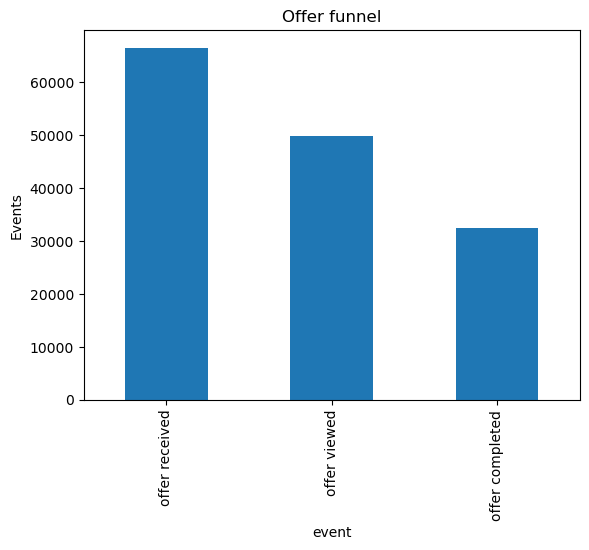

In [37]:
funnel = offers_full['event'].value_counts()[['offer received', 'offer viewed', 'offer completed']]
print(funnel)
print('Viewed % of received:', round(funnel['offer viewed'] / funnel['offer received'] * 100, 1))
print('Completed % of received:', round(funnel['offer completed'] / funnel['offer received'] * 100, 1))

funnel.plot(kind='bar', title='Offer funnel')
plt.ylabel('Events')
plt.show()

In [38]:
by_type = offers_full.groupby(['offer_type', 'event']).size().unstack(fill_value=0)
by_type['view_rate'] = by_type['offer viewed'] / by_type['offer received']
by_type['completion_rate'] = by_type['offer completed'] / by_type['offer received']
by_type

event,offer completed,offer received,offer viewed,view_rate,completion_rate
offer_type,,,,,
bogo,15258,26537,22039,0.830501,0.574971
discount,17186,26664,18461,0.692357,0.644539
informational,0,13300,9360,0.703759,0.000000


In [39]:
by_offer = offers_full.groupby(['offer_id', 'event']).size().unstack(fill_value=0)
by_offer['completion_rate'] = by_offer['offer completed'] / by_offer['offer received']
by_offer = by_offer.merge(portfolio[['offer_id', 'offer_type', 'difficulty', 'reward', 'duration']],
                          left_index=True, right_on='offer_id')
by_offer.sort_values('completion_rate', ascending=False)

,offer completed,offer received,offer viewed,completion_rate,offer_id,offer_type,difficulty,reward,duration
6,5003,6652,6407,0.752105,fafdcd668e3743c1bb461111dcafc2a4,discount,10,2,10
5,4886,6655,6379,0.734185,2298d6c36e964ae4a3e7e9706d1fb8c2,discount,7,3,7
3,4188,6685,3499,0.626477,9b98b8c7a33c4b65b9aebfe6a799e6d9,bogo,5,5,7
8,4103,6576,6310,0.623936,f19421c1d4aa40978ebb69ca19b0e20d,bogo,5,5,5
9,3911,6631,3460,0.589805,2906b810c7d4411798c6938adc9daaa5,discount,10,2,7
0,3657,6683,5901,0.547209,ae264e3637204a6fb9bb56bc8210ddfd,bogo,10,10,7
4,3386,6726,2215,0.503420,0b1e1539f2cc45b7b9fa7c272da2e1d7,discount,20,5,10
1,3310,6593,6329,0.502048,4d5c57ea9a6940dd891ad53e9dbe8da0,bogo,10,10,5
7,0,6643,5873,0.000000,5a8bc65990b245e5a138643cd4eb9837,informational,0,0,3
2,0,6657,3487,0.000000,3f207df678b143eea3cee63160fa8bed,informational,0,0,4


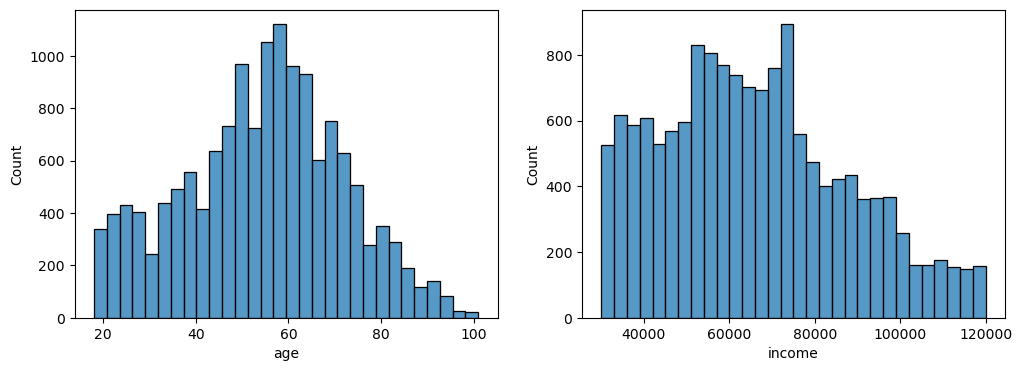

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(customers['age'], bins=30, ax=ax[0])
sns.histplot(customers['income'], bins=30, ax=ax[1])
plt.show()

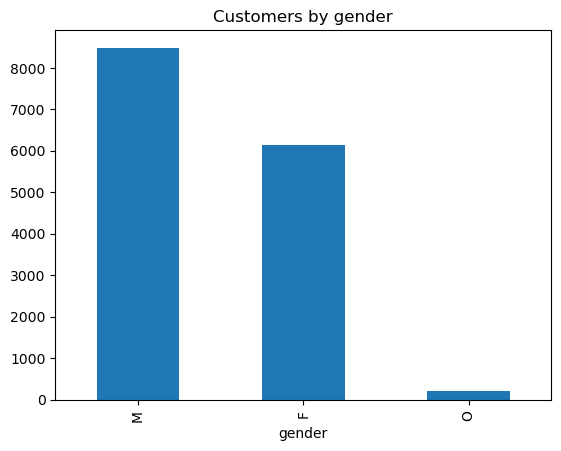

In [41]:
customers['gender'].value_counts().plot(kind='bar', title='Customers by gender')
plt.show()

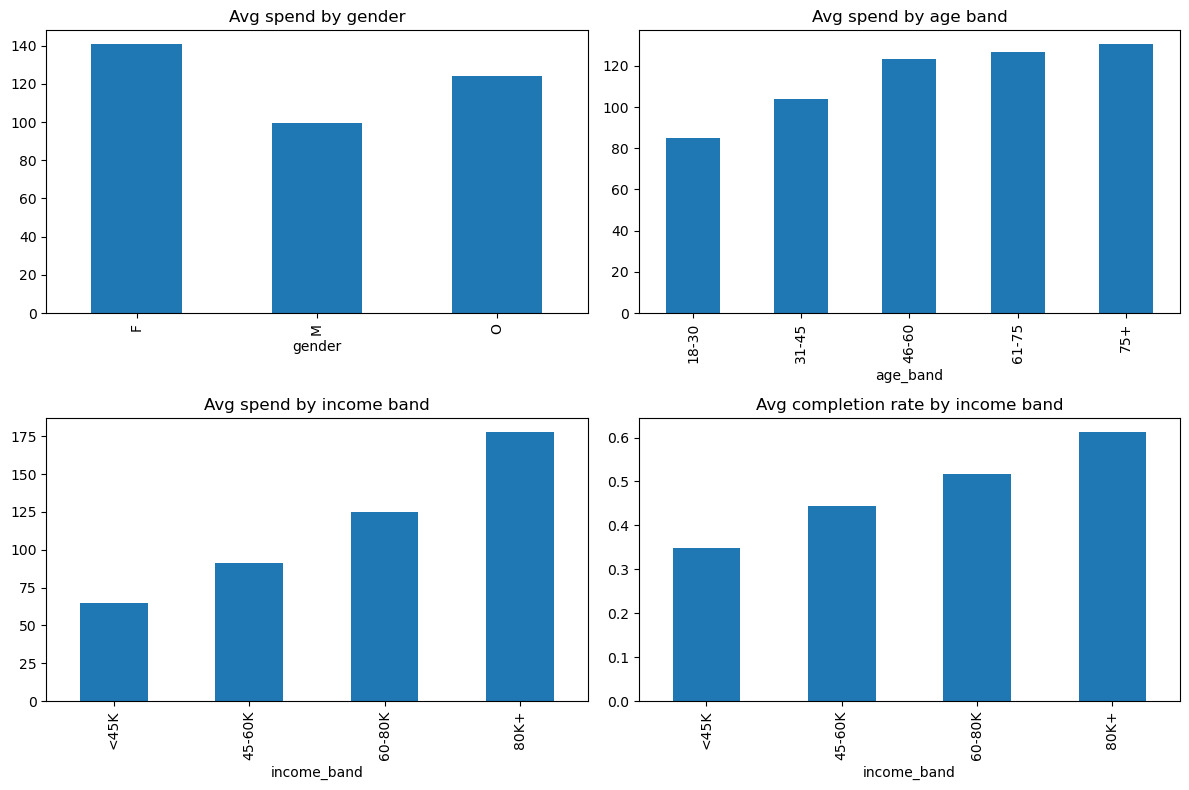

In [42]:
customers['age_band'] = pd.cut(customers['age'], [17, 30, 45, 60, 75, 110],
                               labels=['18-30', '31-45', '46-60', '61-75', '75+'])
customers['income_band'] = pd.cut(customers['income'], [0, 45000, 60000, 80000, 120000],
                                  labels=['<45K', '45-60K', '60-80K', '80K+'])

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
customers.groupby('gender')['total_spend'].mean().plot(kind='bar', ax=ax[0, 0], title='Avg spend by gender')
customers.groupby('age_band', observed=True)['total_spend'].mean().plot(kind='bar', ax=ax[0, 1], title='Avg spend by age band')
customers.groupby('income_band', observed=True)['total_spend'].mean().plot(kind='bar', ax=ax[1, 0], title='Avg spend by income band')
customers.groupby('income_band', observed=True)['completion_rate'].mean().plot(kind='bar', ax=ax[1, 1], title='Avg completion rate by income band')
plt.tight_layout()
plt.show()

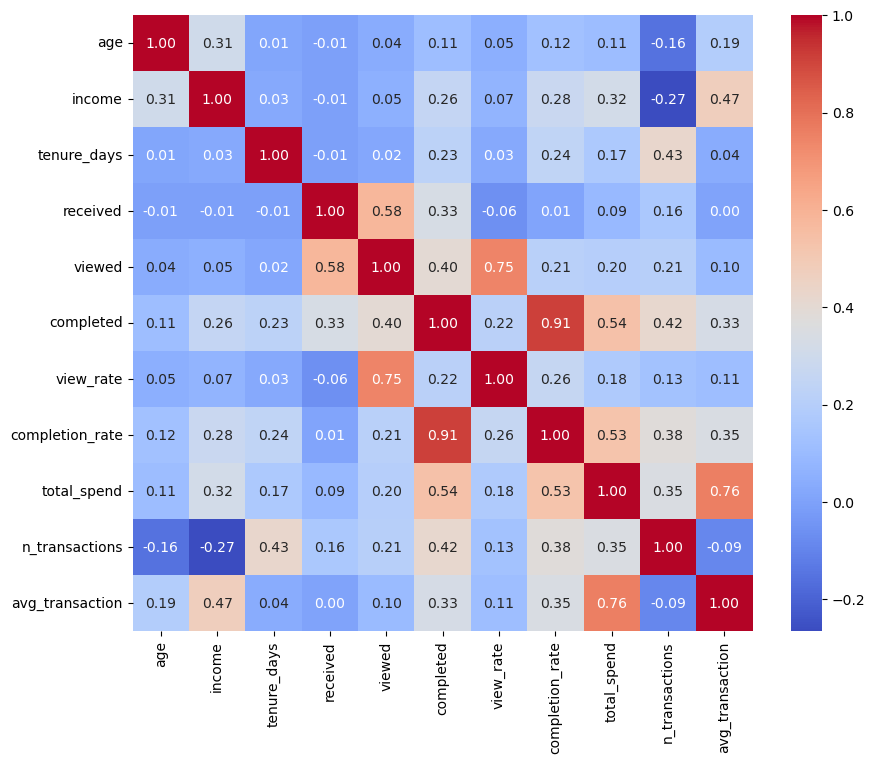

In [43]:
num_cols = ['age', 'income', 'tenure_days', 'received', 'viewed', 'completed',
            'view_rate', 'completion_rate', 'total_spend', 'n_transactions', 'avg_transaction']
plt.figure(figsize=(10, 8))
sns.heatmap(customers[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [44]:
features = ['age', 'income', 'tenure_days', 'view_rate',
            'completion_rate', 'total_spend', 'n_transactions']

In [45]:
customers[features].skew().round(2)
customers['total_spend'].describe()

count    14825.000000
mean       117.028155
std        129.965016
min          0.000000
25%         31.450000
50%         87.040000
75%        160.900000
max       1608.690000
Name: total_spend, dtype: float64

In [46]:
customers['total_spend_log'] = np.log1p(customers['total_spend'])
customers['n_transactions_log'] = np.log1p(customers['n_transactions'])

In [47]:
X = customers[features + ['gender']].copy()
X = pd.get_dummies(X, columns=['gender'], drop_first=True)
X.head()

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,gender_M,gender_O
0,55,112000.0,376,0.000000,0.500000,77.01,3.0,False,False
1,75,100000.0,443,1.000000,0.750000,159.27,7.0,False,False
2,68,70000.0,91,0.750000,0.500000,57.73,3.0,True,False
3,65,53000.0,167,1.000000,0.833333,36.43,3.0,True,False
4,58,51000.0,257,0.666667,0.333333,15.62,4.0,True,False


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.describe().round(2)

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,gender_M,gender_O
count,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00
mean,-0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.09,-1.64,-1.25,-3.18,-1.47,-0.90,-1.61,-1.16,-0.12
25%,-0.71,-0.76,-0.75,-0.65,-0.87,-0.66,-0.84,-1.16,-0.12
50%,0.03,-0.07,-0.39,0.20,0.04,-0.23,-0.26,0.86,-0.12
75%,0.67,0.68,0.65,1.04,0.79,0.34,0.51,0.86,-0.12
max,2.68,2.53,3.10,1.04,1.55,11.48,5.33,0.86,8.30


In [49]:
print(X_scaled.shape)
print(X_scaled.isna().sum().sum())

(14825, 9)
0


In [50]:
X['total_spend'].skew(), X['n_transactions'].skew()   

(np.float64(3.5755349866022277), np.float64(0.8835013004518639))

In [51]:
X['total_spend'] = np.log1p(X['total_spend'])
X['n_transactions'] = np.log1p(X['n_transactions'])

X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.describe().round(2)

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,gender_M,gender_O
count,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00,14825.00
mean,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.09,-1.64,-1.25,-3.18,-1.47,-3.40,-3.27,-1.16,-0.12
25%,-0.71,-0.76,-0.75,-0.65,-0.87,-0.59,-0.72,-1.16,-0.12
50%,0.03,-0.07,-0.39,0.20,0.04,0.22,0.02,0.86,-0.12
75%,0.67,0.68,0.65,1.04,0.79,0.71,0.67,0.86,-0.12
max,2.68,2.53,3.10,1.04,1.55,2.56,2.45,0.86,8.30


In [52]:
from sklearn.decomposition import PCA

pca_full = PCA()
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

for i, (e, c) in enumerate(zip(explained, cum_explained), start=1):
    print(f'PC{i}: {e:.3f}  cumulative: {c:.3f}')

PC1: 0.290  cumulative: 0.290
PC2: 0.181  cumulative: 0.471
PC3: 0.120  cumulative: 0.591
PC4: 0.107  cumulative: 0.698
PC5: 0.093  cumulative: 0.791
PC6: 0.079  cumulative: 0.870
PC7: 0.076  cumulative: 0.946
PC8: 0.039  cumulative: 0.985
PC9: 0.015  cumulative: 1.000


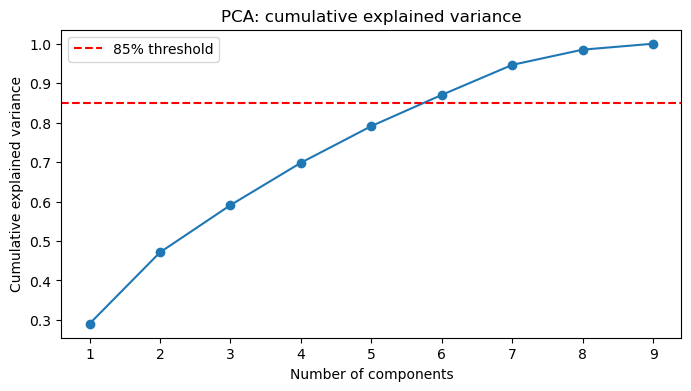

In [53]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_explained) + 1), cum_explained, marker='o')
plt.axhline(0.85, color='red', linestyle='--', label='85% threshold')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA: cumulative explained variance')
plt.legend()
plt.show()

In [54]:
n_components = np.argmax(cum_explained >= 0.85) + 1
print('Components needed for 85% variance:', n_components)

Components needed for 85% variance: 6


In [55]:
pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(X_pca.shape)

(14825, 6)


In [56]:
loadings = pd.DataFrame(pca.components_.T,
                        columns=[f'PC{i+1}' for i in range(n_components)],
                        index=X_scaled.columns)
loadings.round(2)

,PC1,PC2,PC3,PC4,PC5,PC6
age,0.11,0.48,-0.24,-0.09,0.53,-0.45
income,0.21,0.56,-0.23,-0.04,-0.00,0.54
tenure_days,0.30,-0.27,-0.16,-0.40,0.47,-0.12
view_rate,0.22,0.05,0.20,0.83,0.22,-0.23
completion_rate,0.53,0.05,-0.00,0.08,-0.14,0.16
total_spend,0.57,-0.00,-0.04,0.00,-0.14,0.15
n_transactions,0.42,-0.47,0.04,-0.09,-0.05,-0.14
gender_M,-0.17,-0.39,-0.36,0.28,0.49,0.54
gender_O,0.03,0.09,0.83,-0.19,0.41,0.30


In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

results = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_pca)
    results.append({
        'k': k,
        'wcss': km.inertia_,
        'silhouette': silhouette_score(X_pca, labels),
        'calinski_harabasz': calinski_harabasz_score(X_pca, labels)
    })

scores = pd.DataFrame(results)
scores.round(3)

,k,wcss,silhouette,calinski_harabasz
0,2,88874.097,0.246,4545.514
1,3,74245.893,0.263,4180.515
2,4,61989.436,0.222,4314.637
3,5,56250.965,0.211,3943.817
4,6,51041.029,0.216,3779.429
5,7,46874.242,0.206,3648.766
6,8,43603.847,0.204,3520.620
7,9,40737.997,0.209,3427.308
8,10,38433.453,0.208,3327.670


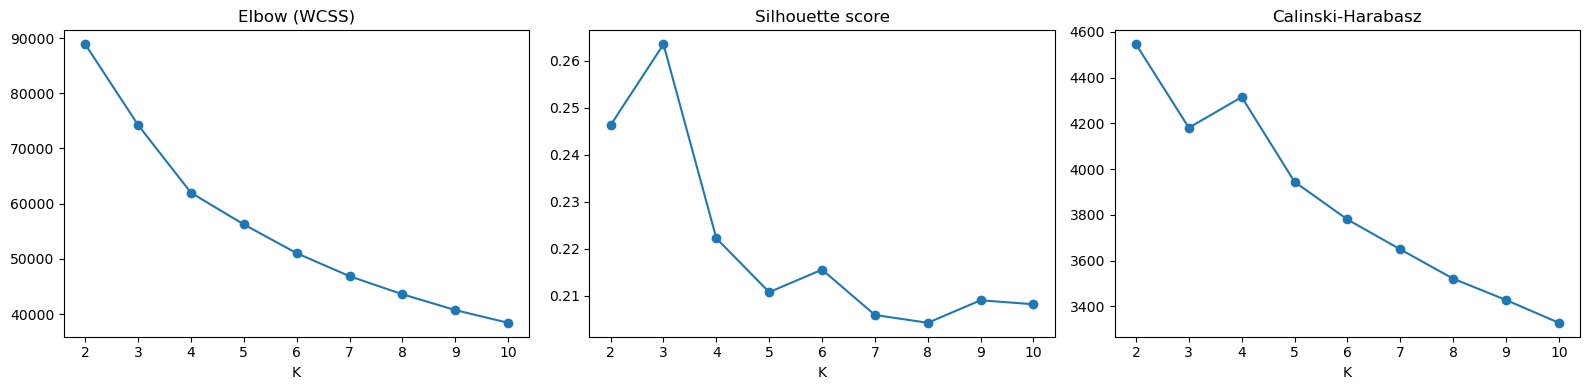

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(scores.k, scores.wcss, marker='o'); ax[0].set_title('Elbow (WCSS)')
ax[1].plot(scores.k, scores.silhouette, marker='o'); ax[1].set_title('Silhouette score')
ax[2].plot(scores.k, scores.calinski_harabasz, marker='o'); ax[2].set_title('Calinski-Harabasz')
for a in ax:
    a.set_xlabel('K')
plt.tight_layout()
plt.show()

In [59]:
final_k = 4
kmeans = KMeans(n_clusters=final_k, n_init=10, random_state=42)
customers['cluster'] = kmeans.fit_predict(X_pca)
customers['cluster'].value_counts().sort_index()

cluster
0    5021
1    4257
2    5335
3     212
Name: count, dtype: int64

In [60]:
wcss = kmeans.inertia_
tss = ((X_pca - X_pca.mean(axis=0)) ** 2).sum()
bcss = tss - wcss
print('WCSS:', round(wcss, 1))
print('BCSS:', round(bcss, 1))
print('BCSS / TSS:', round(bcss / tss, 3))

WCSS: 61989.4
BCSS: 54138.1
BCSS / TSS: 0.466


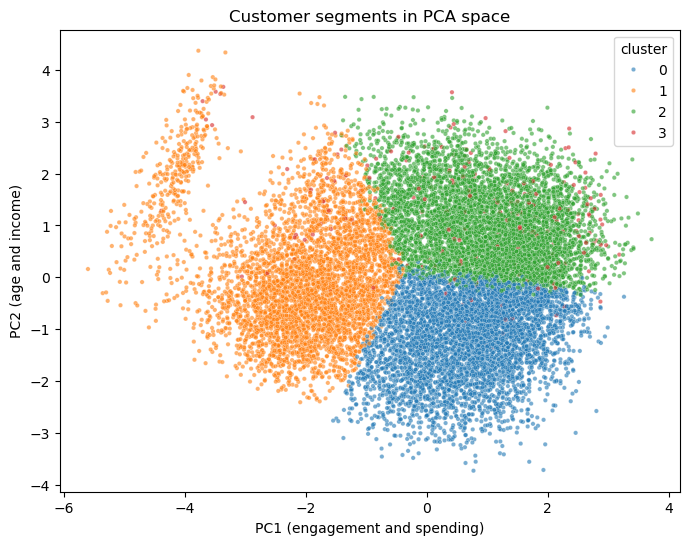

In [61]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=customers['cluster'],
                palette='tab10', s=10, alpha=0.6)
plt.xlabel('PC1 (engagement and spending)')
plt.ylabel('PC2 (age and income)')
plt.title('Customer segments in PCA space')
plt.show()

In [62]:
print(customers['cluster'].value_counts().sort_index())
print((customers['cluster'].value_counts(normalize=True).sort_index() * 100).round(1))
pd.crosstab(customers['cluster'], customers['gender'])

cluster
0    5021
1    4257
2    5335
3     212
Name: count, dtype: int64
cluster
0    33.9
1    28.7
2    36.0
3     1.4
Name: proportion, dtype: float64


gender,F,M,O
cluster,,,
0,1364,3657,0
1,1073,3184,0
2,3692,1643,0
3,0,0,212


In [63]:
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_pca)
    tss = ((X_pca - X_pca.mean(axis=0)) ** 2).sum()
    print(k, 'silhouette:', round(silhouette_score(X_pca, lab), 3),
          'BCSS/TSS:', round((tss - km.inertia_) / tss, 3),
          'sizes:', np.bincount(lab))

3 silhouette: 0.263 BCSS/TSS: 0.361 sizes: [9500 5113  212]
4 silhouette: 0.222 BCSS/TSS: 0.466 sizes: [5021 4257 5335  212]


In [64]:
final_k = 3
kmeans = KMeans(n_clusters=final_k, n_init=10, random_state=42)
customers['cluster'] = kmeans.fit_predict(X_pca)
customers['cluster'].value_counts().sort_index()

cluster
0    9500
1    5113
2     212
Name: count, dtype: int64

In [65]:
profile_cols = ['age', 'income', 'tenure_days', 'view_rate', 'completion_rate',
                'total_spend', 'n_transactions', 'avg_transaction']

cluster_profile = customers.groupby('cluster')[profile_cols].mean().round(2)
cluster_profile['size'] = customers['cluster'].value_counts().sort_index()
cluster_profile['share_%'] = (cluster_profile['size'] / len(customers) * 100).round(1)
cluster_profile

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,avg_transaction,size,share_%
cluster,,,,,,,,,,
0,56.28,69818.74,662.72,0.80,0.67,164.99,10.27,18.96,9500,64.1
1,50.89,57292.00,263.38,0.67,0.15,27.61,4.82,7.40,5113,34.5
2,54.40,63287.74,487.18,0.85,0.55,124.32,8.40,14.55,212,1.4


In [66]:
pd.crosstab(customers['cluster'], customers['gender'], normalize='index').round(2)

gender,F,M,O
cluster,,,
0,0.50,0.50,0.0
1,0.27,0.73,0.0
2,0.00,0.00,1.0


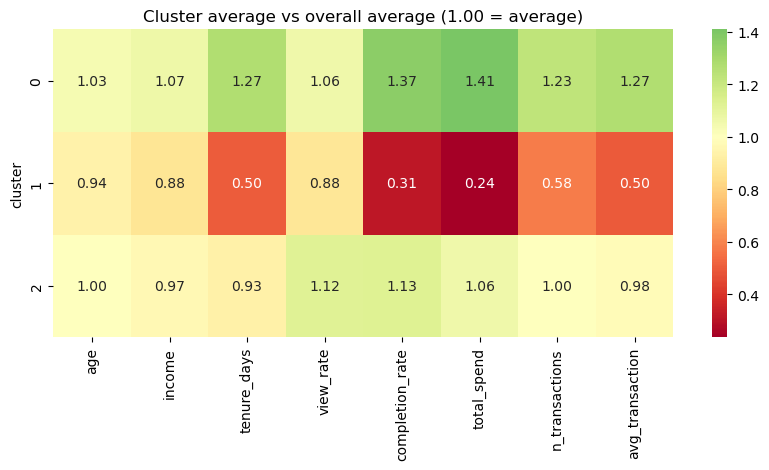

In [67]:
rel = customers.groupby('cluster')[profile_cols].mean() / customers[profile_cols].mean()
plt.figure(figsize=(10, 4))
sns.heatmap(rel, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Cluster average vs overall average (1.00 = average)')
plt.show()

In [68]:
X2 = X.drop(columns=[c for c in X.columns if c.startswith('gender_')])
X2_scaled = pd.DataFrame(StandardScaler().fit_transform(X2), columns=X2.columns, index=X2.index)
X2_scaled.shape

(14825, 7)

In [69]:
pca2_full = PCA().fit(X2_scaled)
cum2 = np.cumsum(pca2_full.explained_variance_ratio_)
n2 = np.argmax(cum2 >= 0.85) + 1
print('Components for 85% variance:', n2)

pca2 = PCA(n_components=n2, random_state=42)
X2_pca = pca2.fit_transform(X2_scaled)

Components for 85% variance: 5


In [70]:
results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X2_pca)
    tss = ((X2_pca - X2_pca.mean(axis=0)) ** 2).sum()
    results.append({'k': k, 'wcss': km.inertia_,
                    'silhouette': silhouette_score(X2_pca, lab),
                    'calinski_harabasz': calinski_harabasz_score(X2_pca, lab),
                    'bcss_tss': (tss - km.inertia_) / tss,
                    'smallest_cluster_%': np.bincount(lab).min() / len(lab) * 100})
pd.DataFrame(results).round(3)

,k,wcss,silhouette,calinski_harabasz,bcss_tss,smallest_cluster_%
0,2,69847.421,0.267,5676.089,0.277,34.995
1,3,58374.468,0.218,4852.198,0.396,29.693
2,4,52520.202,0.209,4145.844,0.456,14.415
3,5,47688.833,0.197,3799.504,0.506,12.702
4,6,43582.861,0.195,3604.965,0.549,10.664
5,7,39923.425,0.209,3505.631,0.587,2.934
6,8,37486.303,0.203,3337.601,0.612,2.880


In [71]:
final_k = 3   
kmeans = KMeans(n_clusters=final_k, n_init=10, random_state=42)
customers['cluster'] = kmeans.fit_predict(X2_pca)

In [72]:
customers.groupby('cluster')[profile_cols].mean().round(2)
pd.crosstab(customers['cluster'], customers['gender'], normalize='index').round(2)
customers['cluster'].value_counts(normalize=True).sort_index().round(3)

cluster
0    0.330
1    0.373
2    0.297
Name: proportion, dtype: float64

In [73]:
customers.groupby('cluster')[profile_cols].mean().round(2)

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,avg_transaction
cluster,,,,,,,,
0,45.92,51512.47,767.91,0.78,0.59,129.35,13.14,10.70
1,64.26,84634.24,548.31,0.80,0.69,181.11,7.36,25.23
2,51.41,56682.87,217.28,0.67,0.13,22.82,4.31,6.62


In [74]:
pd.crosstab(customers['cluster'], customers['gender'], normalize='index').round(2)

gender,F,M,O
cluster,,,
0,0.36,0.63,0.02
1,0.56,0.42,0.01
2,0.29,0.70,0.01


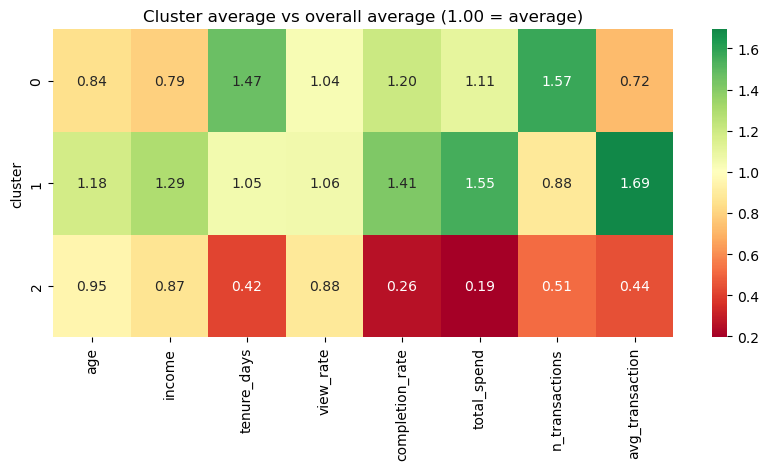

In [75]:
rel = customers.groupby('cluster')[profile_cols].mean() / customers[profile_cols].mean()
plt.figure(figsize=(10, 4))
sns.heatmap(rel, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Cluster average vs overall average (1.00 = average)')
plt.show()

In [76]:
offers_seg = offers_full.merge(customers[['person', 'cluster']], on='person', how='inner')

ev = offers_seg.groupby(['cluster', 'offer_type', 'event']).size().unstack(fill_value=0)
ev['view_rate'] = ev['offer viewed'] / ev['offer received']
ev['completion_rate'] = ev['offer completed'] / ev['offer received']
ev.round(3)

event                  offer completed  offer received  offer viewed  \
cluster offer_type                                                     
0       bogo                      5904            9001          7704   
        discount                  7158            8922          6284   
        informational                0            4404          3339   
1       bogo                      8288           10030          8510   
        discount                  8628            9983          7629   
        informational                0            4643          3403   
2       bogo                      1066            7506          5825   
        discount                  1400            7759          4548   
        informational                0            4253          2618   

event                  view_rate  completion_rate  
cluster offer_type                                 
0       bogo               0.856            0.656  
        discount           0.704            0.802  
        informational      0.758            0.000  
1       bogo               0.848            0.826  
        discount           0.764            0.864  
        informational      0.733            0.000  
2       bogo               0.776            0.142  
        discount           0.586            0.180  
        informational      0.616            0.000

In [77]:
customers.groupby('cluster')[profile_cols].mean().round(2)

,age,income,tenure_days,view_rate,completion_rate,total_spend,n_transactions,avg_transaction
cluster,,,,,,,,
0,45.92,51512.47,767.91,0.78,0.59,129.35,13.14,10.70
1,64.26,84634.24,548.31,0.80,0.69,181.11,7.36,25.23
2,51.41,56682.87,217.28,0.67,0.13,22.82,4.31,6.62


In [78]:
pd.crosstab(customers['cluster'], customers['gender'], normalize='index').round(2)

gender,F,M,O
cluster,,,
0,0.36,0.63,0.02
1,0.56,0.42,0.01
2,0.29,0.70,0.01


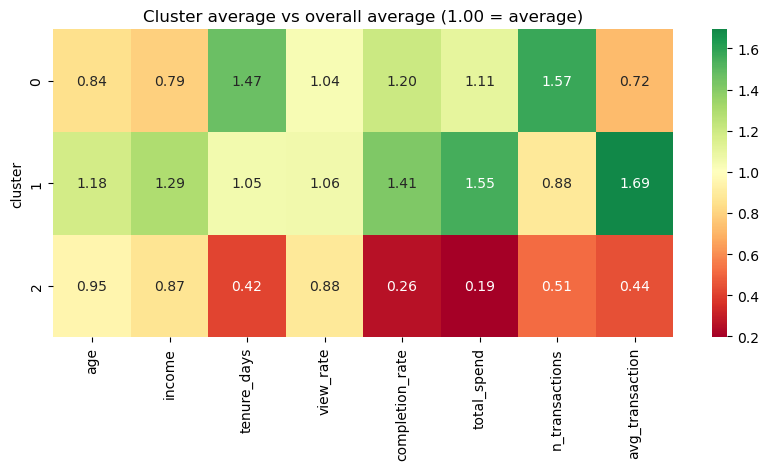

In [79]:
rel = customers.groupby('cluster')[profile_cols].mean() / customers[profile_cols].mean()
plt.figure(figsize=(10, 4))
sns.heatmap(rel, annot=True, fmt='.2f', cmap='RdYlGn', center=1)
plt.title('Cluster average vs overall average (1.00 = average)')
plt.show()